In [46]:
# Core data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, PowerTransformer

# Model
from sklearn.linear_model import LogisticRegression

# Evaluation
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# Imbalanced data handling
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Pipelines
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Cosmetic
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [47]:
# Load the Pima Indians Diabetes dataset
df = pd.read_csv("data/diabetes.csv")

# Peek at the first few rows
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [48]:
# Shape: (number_of_rows, number_of_columns)
print("Shape:", df.shape)

# Data types of every column
print("\nData types:\n", df.dtypes)

# Summary statistics for every numeric column
df.describe()

Shape: (768, 9)

Data types:
 Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [49]:
# X = every column except the target -> the FEATURES the model learns from
X = df.drop(columns=["Outcome"])

# y = only the target column -> the LABEL the model must predict
y = df["Outcome"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (768, 8)
y shape: (768,)


Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64


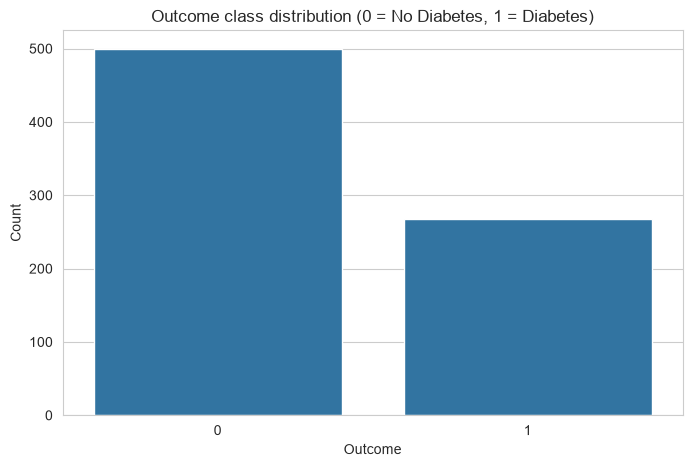

In [50]:
# Raw counts per class
print(y.value_counts())

# Proportion (percentage) per class
print(y.value_counts(normalize=True))

# Visualize the class distribution
sns.countplot(x=y)
plt.title("Outcome class distribution (0 = No Diabetes, 1 = Diabetes)")
plt.xlabel("Outcome")
plt.ylabel("Count")
plt.show()

In [51]:
# These columns are PHYSIOLOGICALLY IMPOSSIBLE at zero.
# A living patient cannot have 0 Glucose, 0 BloodPressure, 0 BMI, etc.
# A recorded 0 in these columns means "not measured", not "value is zero".
cols_with_invalid_zero = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

# Count how many zeros exist in each of these columns
for col in cols_with_invalid_zero:
    n_zero = (df[col] == 0).sum()
    print(f"{col}: {n_zero} zero-values ({n_zero / len(df) * 100:.1f}% of rows)")

Glucose: 5 zero-values (0.7% of rows)
BloodPressure: 35 zero-values (4.6% of rows)
SkinThickness: 227 zero-values (29.6% of rows)
Insulin: 374 zero-values (48.7% of rows)
BMI: 11 zero-values (1.4% of rows)


In [52]:
X[cols_with_invalid_zero].isnull().sum()

Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

In [53]:
# Replace the impossible 0s with NaN so they are treated as MISSING,
# not as a legitimate measurement of zero.
X[cols_with_invalid_zero] = X[cols_with_invalid_zero].replace(0, np.nan)

# Confirm: these columns now show missing values instead of silent zeros
X[cols_with_invalid_zero].isnull().sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

In [54]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [55]:
print("Full dataset class proportions:")
print(y.value_counts(normalize=True), "\n")

print("y_train class proportions:")
print(y_train.value_counts(normalize=True), "\n")

print("y_test class proportions:")
print(y_test.value_counts(normalize=True))

Full dataset class proportions:
Outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64 

y_train class proportions:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64 

y_test class proportions:
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


In [56]:
# Fit the imputer ONLY on training data (learn the median from X_train)
imputer = SimpleImputer(strategy="median")
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Re-use the SAME fitted imputer to transform the test data
# (we do NOT re-fit on X_test -- that would be data leakage)
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Confirm no missing values remain
print(X_train_imputed.isnull().sum().sum(), "missing values left in X_train_imputed")
print(X_test_imputed.isnull().sum().sum(), "missing values left in X_test_imputed")

# From this point on, X_train / X_test refer to the CLEANED (imputed) features.
# Every later step -- transformation, scaling, resampling -- builds on this
# already-clean, leakage-safe foundation.
X_train = X_train_imputed
X_test = X_test_imputed

0 missing values left in X_train_imputed
0 missing values left in X_test_imputed


Insulin                     3.076431
DiabetesPedigreeFunction    1.818910
Age                         1.128456
Pregnancies                 0.886920
SkinThickness               0.886446
BMI                         0.573822
Glucose                     0.556834
BloodPressure               0.115048
dtype: float64


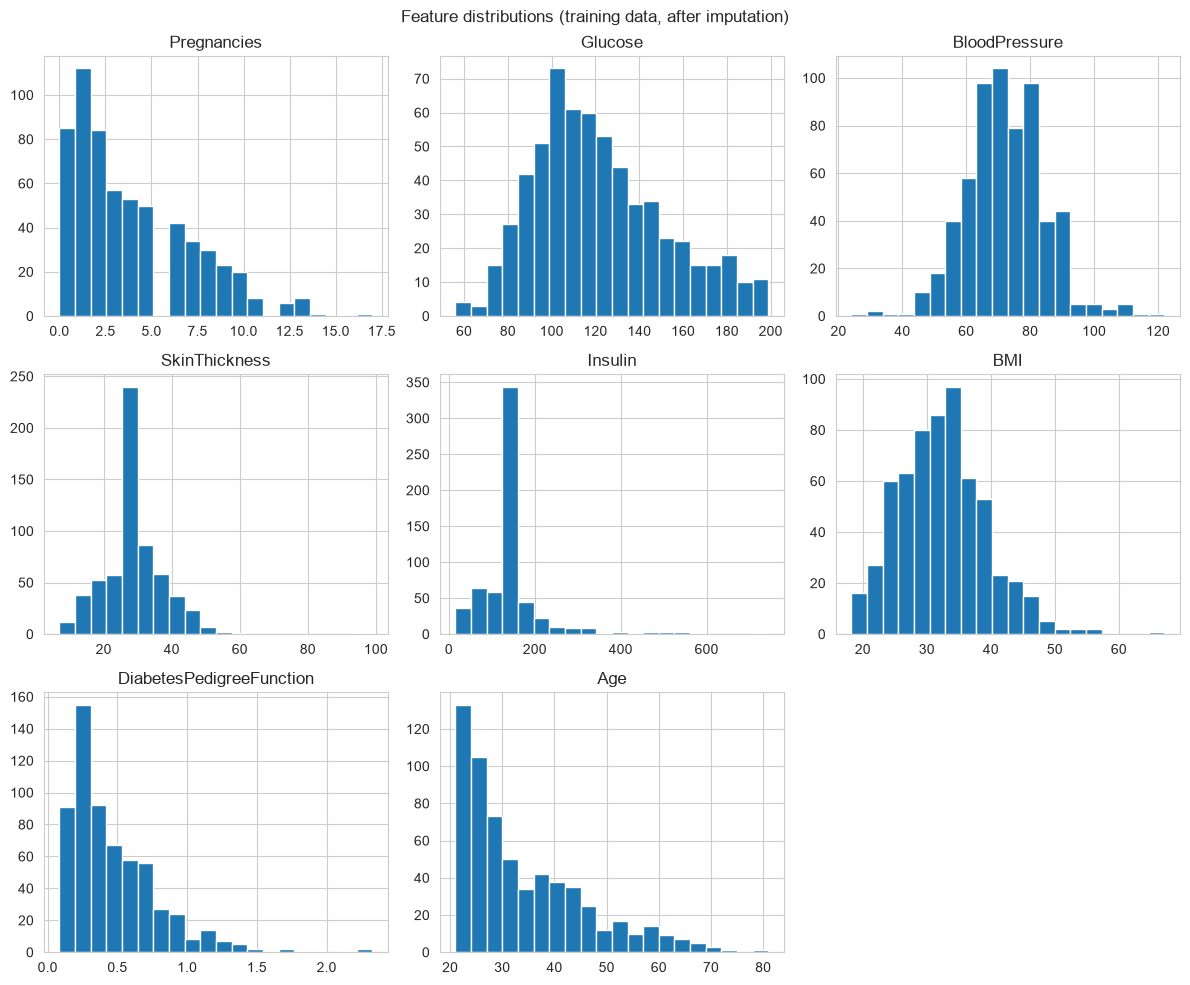

In [57]:
# Check skewness of every feature in the (imputed) training data
skew_values = X_train_imputed.skew().sort_values(ascending=False)
print(skew_values)

# Visualize distributions
X_train_imputed.hist(figsize=(12, 10), bins=20)
plt.suptitle("Feature distributions (training data, after imputation)")
plt.tight_layout()
plt.show()

In [58]:
from sklearn.preprocessing import PowerTransformer

transformer = PowerTransformer(method="yeo-johnson")

# Fit on TRAIN ONLY, then transform both
X_train_transformed = pd.DataFrame(
    transformer.fit_transform(X_train_imputed),
    columns=X_train_imputed.columns,
    index=X_train_imputed.index
)
X_test_transformed = pd.DataFrame(
    transformer.transform(X_test_imputed),
    columns=X_test_imputed.columns,
    index=X_test_imputed.index
)

# Compare skew before vs after transformation
print("Skew BEFORE transform:\n", X_train_imputed.skew(), "\n")
print("Skew AFTER transform:\n", X_train_transformed.skew())

Skew BEFORE transform:
 Pregnancies                 0.886920
Glucose                     0.556834
BloodPressure               0.115048
SkinThickness               0.886446
Insulin                     3.076431
BMI                         0.573822
DiabetesPedigreeFunction    1.818910
Age                         1.128456
dtype: float64 

Skew AFTER transform:
 Pregnancies                -0.045054
Glucose                     0.000693
BloodPressure               0.071570
SkinThickness               0.111136
Insulin                     0.054991
BMI                        -0.000118
DiabetesPedigreeFunction    0.135866
Age                         0.145955
dtype: float64


In [59]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [60]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [61]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

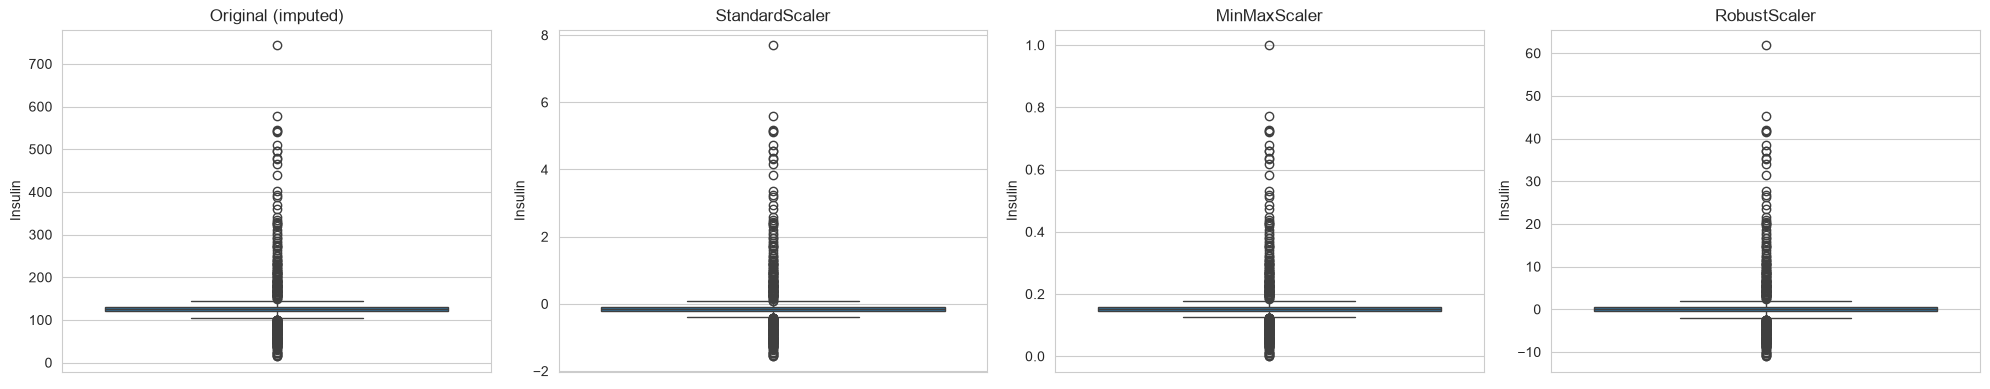

In [62]:
# Compare the effect of each scaler on one feature: Insulin (heavily skewed, with outliers)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

sns.boxplot(y=X_train_imputed["Insulin"], ax=axes[0])
axes[0].set_title("Original (imputed)")

std_demo = StandardScaler().fit_transform(X_train_imputed)
sns.boxplot(y=pd.DataFrame(std_demo, columns=X_train_imputed.columns)["Insulin"], ax=axes[1])
axes[1].set_title("StandardScaler")

mm_demo = MinMaxScaler().fit_transform(X_train_imputed)
sns.boxplot(y=pd.DataFrame(mm_demo, columns=X_train_imputed.columns)["Insulin"], ax=axes[2])
axes[2].set_title("MinMaxScaler")

rob_demo = RobustScaler().fit_transform(X_train_imputed)
sns.boxplot(y=pd.DataFrame(rob_demo, columns=X_train_imputed.columns)["Insulin"], ax=axes[3])
axes[3].set_title("RobustScaler")

plt.tight_layout()
plt.show()

In [63]:
# Experiment A: raw/imputed features, no scaling, no transform, no balancing
model_a = LogisticRegression(random_state=42, max_iter=1000)
model_a.fit(X_train_imputed, y_train)

y_pred_a = model_a.predict(X_test_imputed)

print(classification_report(y_test, y_pred_a))
print(confusion_matrix(y_test, y_pred_a))

              precision    recall  f1-score   support

           0       0.75      0.81      0.78       100
           1       0.59      0.50      0.54        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154

[[81 19]
 [27 27]]


In [64]:
# Raw class counts in the training set
print(y_train.value_counts())

# Proportions
print(y_train.value_counts(normalize=True))

Outcome
0    400
1    214
Name: count, dtype: int64
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64


In [65]:
# A hypothetical, more extreme imbalance for illustration
hypothetical = pd.Series([0] * 900 + [1] * 100)
useless_model_accuracy = (hypothetical == 0).sum() / len(hypothetical)
print(f"Always predicting Class 0 gives accuracy = {useless_model_accuracy:.2%}")
print("...despite the model never once correctly identifying Class 1.")

Always predicting Class 0 gives accuracy = 90.00%
...despite the model never once correctly identifying Class 1.


In [66]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)

# Fit + resample ONLY the training data
X_train_ros, y_train_ros = ros.fit_resample(X_train_scaled, y_train)

print("Before oversampling:", y_train.value_counts().to_dict())
print("After oversampling:", y_train_ros.value_counts().to_dict())

Before oversampling: {0: 400, 1: 214}
After oversampling: {0: 400, 1: 400}


In [67]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)

# Fit + resample ONLY the training data
X_train_rus, y_train_rus = rus.fit_resample(X_train_scaled, y_train)

print("Before undersampling:", y_train.value_counts().to_dict())
print("After undersampling:", y_train_rus.value_counts().to_dict())

Before undersampling: {0: 400, 1: 214}
After undersampling: {0: 214, 1: 214}


In [68]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

# SMOTE is fit and applied ONLY on the training data.
# X_test / y_test are NEVER touched by SMOTE.
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

# print(y_train_smote)

print("Before SMOTE:", y_train.value_counts())
print("After SMOTE:", pd.Series(y_train_smote).value_counts())

Before SMOTE: Outcome
0    400
1    214
Name: count, dtype: int64
After SMOTE: Outcome
0    400
1    400
Name: count, dtype: int64


In [69]:
# Experiment D: StandardScaler + SMOTE + Logistic Regression
model_d = LogisticRegression(random_state=42, max_iter=1000)
model_d.fit(X_train_smote, y_train_smote)

# IMPORTANT: predict on the ORIGINAL, untouched, scaled test set
y_pred_d = model_d.predict(X_test_scaled)

print(classification_report(y_test, y_pred_d))
print(confusion_matrix(y_test, y_pred_d))

              precision    recall  f1-score   support

           0       0.80      0.74      0.77       100
           1       0.57      0.65      0.61        54

    accuracy                           0.71       154
   macro avg       0.68      0.69      0.69       154
weighted avg       0.72      0.71      0.71       154

[[74 26]
 [19 35]]


In [70]:
# Experiment E: StandardScaler + class_weight="balanced" + Logistic Regression
model_e = LogisticRegression(class_weight="balanced", random_state=42, max_iter=1000)
model_e.fit(X_train_scaled, y_train)

y_pred_e = model_e.predict(X_test_scaled)

print(classification_report(y_test, y_pred_e))
print(confusion_matrix(y_test, y_pred_e))

              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154

[[75 25]
 [16 38]]


In [71]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

print(classification_report(y_test, y_pred_a))
print(confusion_matrix(y_test, y_pred_a))

              precision    recall  f1-score   support

           0       0.75      0.81      0.78       100
           1       0.59      0.50      0.54        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154

[[81 19]
 [27 27]]


In [72]:
# Experiment B: StandardScaler + Logistic Regression
model_b = LogisticRegression(random_state=42, max_iter=1000)
model_b.fit(X_train_scaled, y_train)

y_pred_b = model_b.predict(X_test_scaled)

print(classification_report(y_test, y_pred_b))
print(confusion_matrix(y_test, y_pred_b))

              precision    recall  f1-score   support

           0       0.75      0.81      0.78       100
           1       0.59      0.50      0.54        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154

[[81 19]
 [27 27]]


In [73]:
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(random_state=42, max_iter=1000))
])

pipeline.fit(X_train, y_train)
y_pred_pipeline = pipeline.predict(X_test)

print(classification_report(y_test, y_pred_pipeline))
print(confusion_matrix(y_test, y_pred_pipeline))

              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154

[[82 18]
 [27 27]]


In [74]:
from imblearn.pipeline import Pipeline

imb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", LogisticRegression(random_state=42, max_iter=1000))
])

imb_pipeline.fit(X_train, y_train)
y_pred_imb_pipeline = imb_pipeline.predict(X_test)

print(classification_report(y_test, y_pred_imb_pipeline))
print(confusion_matrix(y_test, y_pred_imb_pipeline))

              precision    recall  f1-score   support

           0       0.80      0.74      0.77       100
           1       0.57      0.65      0.61        54

    accuracy                           0.71       154
   macro avg       0.68      0.69      0.69       154
weighted avg       0.72      0.71      0.71       154

[[74 26]
 [19 35]]


In [75]:
# Experiment C: PowerTransformer + StandardScaler + Logistic Regression
scaler_c = StandardScaler()
X_train_c = scaler_c.fit_transform(X_train_transformed)
X_test_c = scaler_c.transform(X_test_transformed)

model_c = LogisticRegression(random_state=42, max_iter=1000)
model_c.fit(X_train_c, y_train)

y_pred_c = model_c.predict(X_test_c)

print(classification_report(y_test, y_pred_c))
print(confusion_matrix(y_test, y_pred_c))

              precision    recall  f1-score   support

           0       0.77      0.83      0.80       100
           1       0.63      0.54      0.58        54

    accuracy                           0.73       154
   macro avg       0.70      0.68      0.69       154
weighted avg       0.72      0.73      0.72       154

[[83 17]
 [25 29]]


In [76]:
def get_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred),
    }

results = pd.DataFrame({
    "A: Raw + LogReg":                  get_metrics(y_test, y_pred_a),
    "B: StandardScaler + LogReg":       get_metrics(y_test, y_pred_b),
    "C: Transform+Scale + LogReg":      get_metrics(y_test, y_pred_c),
    "D: Scale + SMOTE + LogReg":        get_metrics(y_test, y_pred_d),
    "E: Scale + class_weight + LogReg": get_metrics(y_test, y_pred_e),
}).T

results.round(3)

,Accuracy,Precision,Recall,F1-Score
A: Raw + LogReg,0.701,0.587,0.500,0.540
B: StandardScaler + LogReg,0.701,0.587,0.500,0.540
C: Transform+Scale + LogReg,0.727,0.630,0.537,0.580
D: Scale + SMOTE + LogReg,0.708,0.574,0.648,0.609
E: Scale + class_weight + LogReg,0.734,0.603,0.704,0.650


In [77]:
def get_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred),
    }

results = pd.DataFrame({
    "A: Raw + LogReg":                  get_metrics(y_test, y_pred_a),
    "B: StandardScaler + LogReg":       get_metrics(y_test, y_pred_b),
    "C: Transform+Scale + LogReg":      get_metrics(y_test, y_pred_c),
    "D: Scale + SMOTE + LogReg":        get_metrics(y_test, y_pred_d),
    "E: Scale + class_weight + LogReg": get_metrics(y_test, y_pred_e),
}).T

results.round(3)

,Accuracy,Precision,Recall,F1-Score
A: Raw + LogReg,0.701,0.587,0.500,0.540
B: StandardScaler + LogReg,0.701,0.587,0.500,0.540
C: Transform+Scale + LogReg,0.727,0.630,0.537,0.580
D: Scale + SMOTE + LogReg,0.708,0.574,0.648,0.609
E: Scale + class_weight + LogReg,0.734,0.603,0.704,0.650


In [78]:
missing_percentage = df.isnull().mean() * 100
print(missing_percentage)

Pregnancies                 0.0
Glucose                     0.0
BloodPressure               0.0
SkinThickness               0.0
Insulin                     0.0
BMI                         0.0
DiabetesPedigreeFunction    0.0
Age                         0.0
Outcome                     0.0
dtype: float64


In [79]:
df = df.dropna(subset=['Glucose'])

In [80]:
df['Age_imputed'] = df['Age'].fillna(df['Age'].median())

In [81]:
df[''] = df['SkinThickness'].fillna(df['SkinThickness'].mode()[0])

In [82]:
print(df.columns)

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome', 'Age_imputed', ''],
      dtype='str')
